In [ ]:

# ============================================
# 1. IMPORT REQUIRED LIBRARIES
# AI-Based Scam Message Detection
# ============================================

# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Text preprocessing and feature extraction
import re
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

# Train-test split and cross-validation
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate

# Machine Learning models
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# Machine Learning pipeline
from sklearn.pipeline import Pipeline, FeatureUnion

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# Save and load trained models
import joblib

# Reproducibility
import random
import warnings

# Set random seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Hide unnecessary warnings
warnings.filterwarnings("ignore", category=UserWarning)

print("All required libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


All required libraries imported successfully!
Pandas version: 2.2.3
NumPy version: 2.1.3


In [ ]:
df=pd.read_csv("SPAM_SMS.csv")

In [ ]:
df.head()

,masked_celphone_number,hashed_cellphone_number,date,text,carrier
0,789BIngo 5,966f58c9-0fb4-39d1-aef9-54ef479762c1,2026-07-01 09:13:32.668,Login at may 2 FREE Spin! Marami na ang nakaku...,<unknown>
1,+63969****493,691da84b-6868-3a7d-a9b6-efd391f5478e,2026-04-23 01:01:22.884,"Condo across Ateneo by Torre Lorenzo, only 12 ...",Smart
2,+63960****655,355f5386-d208-3c23-80f1-7c406c44de35,2026-03-27 06:23:44.260,"papalduhin kita ng 12k ngayon, basta ikaw na b...",Smart
3,+63960****150,ff1e02ed-2460-32a4-ba00-2cd9c1c0ad8a,2026-02-17 10:25:35.838,"B0ss pan@lunin kita sa pinata win 15k, n0w lan...",Smart
4,+63963****180,206acbf8-c2a4-3d11-8823-22caca6416ee,2026-01-19 16:13:33.766,Dito nagsisimula ang saya at panalo! 8P FREE +...,Smart/TNT


In [ ]:
print(df.shape)

(1021, 5)


In [ ]:
df=pd.read_csv("CEAS_08.csv")

In [ ]:
df.head()

,sender,receiver,date,subject,body,label,urls
0,Young Esposito <Young@iworld.de>,user4@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 16:31:02 -0700",Never agree to be a loser,"Buck up, your troubles caused by small dimensi...",1,1
1,Mok <ipline's1983@icable.ph>,user2.2@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 18:31:03 -0500",Befriend Jenna Jameson,\nUpgrade your sex and pleasures with these te...,1,1
2,Daily Top 10 <Karmandeep-opengevl@universalnet...,user2.9@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 20:28:00 -1200",CNN.com Daily Top 10,>+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+...,1,1
3,Michael Parker <ivqrnai@pobox.com>,SpamAssassin Dev <xrh@spamassassin.apache.org>,"Tue, 05 Aug 2008 17:31:20 -0600",Re: svn commit: r619753 - in /spamassassin/tru...,Would anyone object to removing .so from this ...,0,1
4,Gretchen Suggs <externalsep1@loanofficertool.com>,user2.2@gvc.ceas-challenge.cc,"Tue, 05 Aug 2008 19:31:21 -0400",SpecialPricesPharmMoreinfo,\nWelcomeFastShippingCustomerSupport\nhttp://7...,1,1


In [ ]:
print(df.shape)

(39154, 7)


In [ ]:
sms_df = pd.read_csv("SPAM_SMS.csv", low_memory=False)
email_df = pd.read_csv("CEAS_08.csv", low_memory=False)

def inspect_dataset(df, name):
    print("\\n" + "=" * 75)
    print(name)
    print("=" * 75)
    print("Rows:", len(df))
    print("Columns:", len(df.columns))
    print("Column names:", df.columns.tolist())
    print("\\nData types:\\n", df.dtypes.astype(str).to_string())
    print("\\nMissing values:\\n", df.isna().sum().to_string())
    print("\\nExact duplicate rows:", int(df.duplicated().sum()))
    preview = df.head(5).copy()
    # Do not show email sender/receiver or phone identifier columns in previews.
    sensitive_like = {"sender", "receiver", "masked_celphone_number", "hashed_cellphone_number"}
    preview = preview.drop(columns=[c for c in preview.columns if c.lower() in sensitive_like], errors="ignore")
    for c in preview.select_dtypes(include="object").columns:
        preview[c] = preview[c].fillna("").astype(str).str.replace(r"\\s+", " ", regex=True).str.slice(0, 180)
    display(preview)

inspect_dataset(sms_df, "SMS DATASET")
inspect_dataset(email_df, "CEAS EMAIL DATASET")

if "label" not in email_df.columns:
    raise ValueError("CEAS_08.csv has no 'label' column. Check the file you uploaded.")
print("\\nEmail raw label counts:\\n", email_df["label"].value_counts(dropna=False).sort_index())
print("\\nSMS duplicate message text count:", int(sms_df["text"].fillna("").duplicated().sum()) if "text" in sms_df.columns else "No 'text' column")

\n===========================================================================
SMS DATASET
Rows: 1021
Columns: 5
Column names: ['masked_celphone_number', 'hashed_cellphone_number', 'date', 'text', 'carrier']
\nData types:\n masked_celphone_number     object
hashed_cellphone_number    object
date                       object
text                       object
carrier                    object
\nMissing values:\n masked_celphone_number     0
hashed_cellphone_number    0
date                       0
text                       0
carrier                    0
\nExact duplicate rows: 0


,date,text,carrier
0,2026-07-01 09:13:32.668,Login at may 2 FREE Spin! Marami na ang nakaku...,<unknown>
1,2026-04-23 01:01:22.884,"Condo across Ateneo by Torre Lorenzo, only 12 ...",Smart
2,2026-03-27 06:23:44.260,"papalduhin kita ng 12k ngayon, basta ikaw na b...",Smart
3,2026-02-17 10:25:35.838,"B0ss pan@lunin kita sa pinata win 15k, n0w lan...",Smart
4,2026-01-19 16:13:33.766,Dito nagsisimula ang saya at panalo! 8P FREE +...,Smart/TNT


\n===========================================================================
CEAS EMAIL DATASET
Rows: 39154
Columns: 7
Column names: ['sender', 'receiver', 'date', 'subject', 'body', 'label', 'urls']
\nData types:\n sender      object
receiver    object
date        object
subject     object
body        object
label        int64
urls         int64
\nMissing values:\n sender        0
receiver    462
date          0
subject      28
body          0
label         0
urls          0
\nExact duplicate rows: 0


,date,subject,body,label,urls
0,"Tue, 05 Aug 2008 16:31:02 -0700",Never agree to be a loser,"Buck up, your troubles caused by small dimensi...",1,1
1,"Tue, 05 Aug 2008 18:31:03 -0500",Befriend Jenna Jameson,\nUpgrade your sex and pleasures with these te...,1,1
2,"Tue, 05 Aug 2008 20:28:00 -1200",CNN.com Daily Top 10,>+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+...,1,1
3,"Tue, 05 Aug 2008 17:31:20 -0600",Re: svn commit: r619753 - in /spamassassin/tru...,Would anyone object to removing .so from this ...,0,1
4,"Tue, 05 Aug 2008 19:31:21 -0400",SpecialPricesPharmMoreinfo,\nWelcomeFastShippingCustomerSupport\nhttp://7...,1,1


\nEmail raw label counts:\n label
0    17312
1    21842
Name: count, dtype: int64
\nSMS duplicate message text count: 76


Rows before repeated-content removal: 39154
Rows after repeated-content removal: 39099
Removed: 55


,label,label_name,count,percent
0,0,label_0 (verify meaning),17304,44.26
1,1,label_1 (verify meaning),21795,55.74


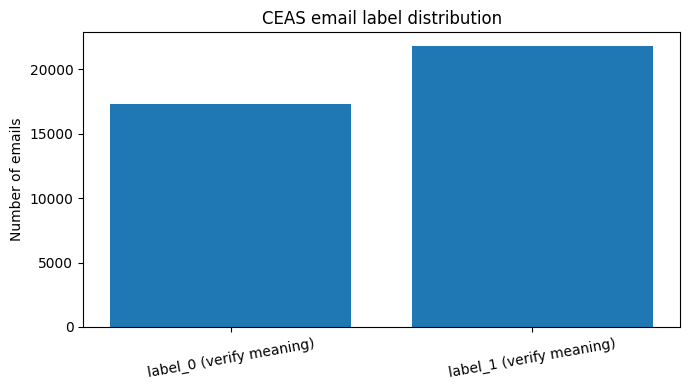

In [ ]:
required = {"subject", "body", "label"}
missing_required = required - set(email_df.columns)
if missing_required:
    raise ValueError(f"CEAS dataset missing required columns: {sorted(missing_required)}")

df = email_df.copy()
df["label"] = pd.to_numeric(df["label"], errors="coerce")
df = df[df["label"].isin([0, 1])].copy()
df["label"] = df["label"].astype(int)

# Verify this label mapping against the original Kaggle dataset description.
LABEL_NAMES = {0: "label_0 (verify meaning)", 1: "label_1 (verify meaning)"}

df["subject"] = df["subject"].fillna("").astype(str)
df["body"] = df["body"].fillna("").astype(str)

# Bound unusually long records to reduce memory use; this is a fixed rule, not learned from test data.
df["subject"] = df["subject"].str.slice(0, 500)
df["body"] = df["body"].str.slice(0, 20000)
df["message_text"] = ("SUBJECT: " + df["subject"].str.strip() +
                      " BODY: " + df["body"].str.strip()).str.strip()

# Remove repeated same-label content to reduce exact duplicate leakage.
before = len(df)
df = df.drop_duplicates(subset=["message_text", "label"]).copy()
print("Rows before repeated-content removal:", before)
print("Rows after repeated-content removal:", len(df))
print("Removed:", before - len(df))

class_counts = df["label"].value_counts().sort_index()
class_summary = pd.DataFrame({
    "label": class_counts.index,
    "label_name": [LABEL_NAMES[int(v)] for v in class_counts.index],
    "count": class_counts.values,
    "percent": (100 * class_counts.values / len(df)).round(2)
})
display(class_summary)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(class_summary["label_name"], class_summary["count"])
ax.set_title("CEAS email label distribution")
ax.set_ylabel("Number of emails")
ax.tick_params(axis="x", rotation=10)
plt.tight_layout()
plt.show()

if set(df["label"].unique()) != {0, 1}:
    raise ValueError("Expected both labels 0 and 1. Inspect the label values and dataset documentation.")

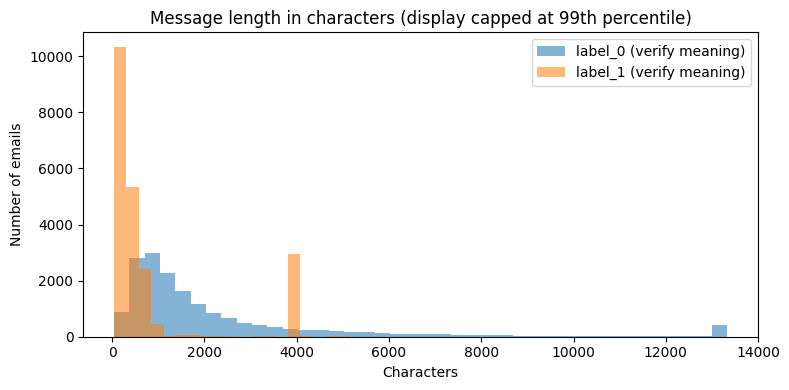

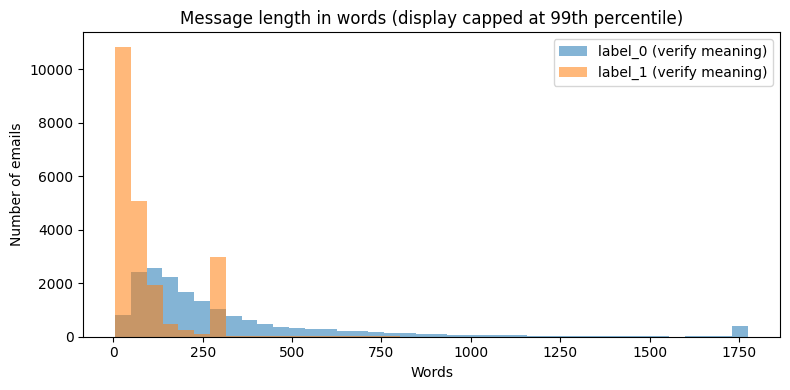

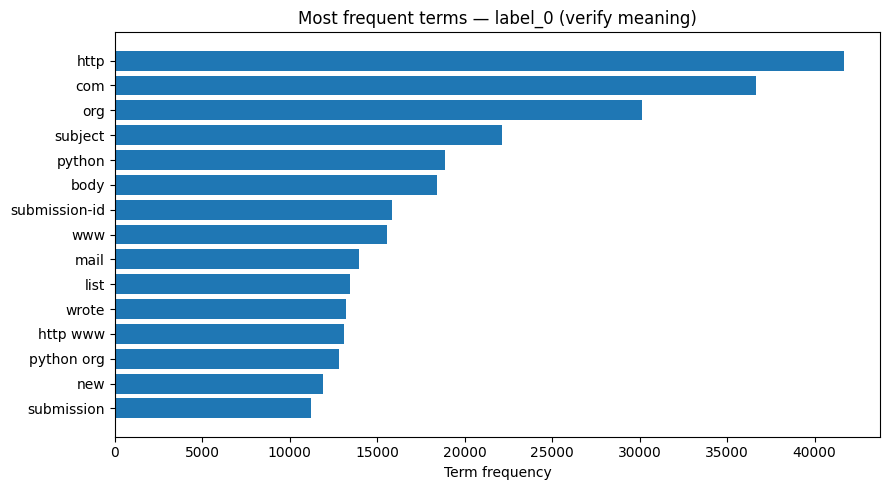

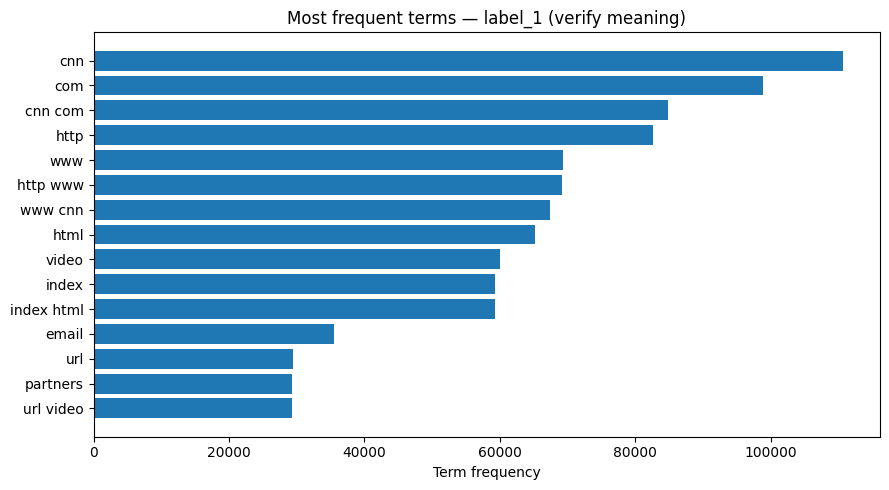

,label_name,subject,body
0,label_1 (verify meaning),Never agree to be a loser,"Buck up, your troubles caused by small dimensi..."
1,label_1 (verify meaning),Befriend Jenna Jameson,Upgrade your sex and pleasures with these tec...
2,label_1 (verify meaning),CNN.com Daily Top 10,>+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+...
3,label_0 (verify meaning),Re: svn commit: r619753 - in /spamassassin/tru...,Would anyone object to removing .so from this ...
4,label_1 (verify meaning),SpecialPricesPharmMoreinfo,WelcomeFastShippingCustomerSupport http://7iw...


In [ ]:
df["length_chars"] = df["message_text"].str.len()
df["length_words"] = df["message_text"].str.split().str.len()

fig, ax = plt.subplots(figsize=(8, 4))
upper = max(1, float(df["length_chars"].quantile(0.99)))
for label in [0, 1]:
    vals = df.loc[df["label"] == label, "length_chars"].clip(upper=upper)
    ax.hist(vals, bins=40, alpha=0.55, label=LABEL_NAMES[label])
ax.set_title("Message length in characters (display capped at 99th percentile)")
ax.set_xlabel("Characters")
ax.set_ylabel("Number of emails")
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
upper_words = max(1, float(df["length_words"].quantile(0.99)))
for label in [0, 1]:
    vals = df.loc[df["label"] == label, "length_words"].clip(upper=upper_words)
    ax.hist(vals, bins=40, alpha=0.55, label=LABEL_NAMES[label])
ax.set_title("Message length in words (display capped at 99th percentile)")
ax.set_xlabel("Words")
ax.set_ylabel("Number of emails")
ax.legend()
plt.tight_layout()
plt.show()

def show_common_terms(data, label, top_n=15):
    texts = data.loc[data["label"] == label, "message_text"].fillna("")
    vectorizer = CountVectorizer(
        stop_words="english", ngram_range=(1, 2), min_df=2,
        max_features=25000, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z0-9_'-]+\b"
    )
    try:
        matrix = vectorizer.fit_transform(texts)
    except ValueError as e:
        print(f"Could not generate terms for {LABEL_NAMES[label]}: {e}")
        return

    totals = np.asarray(matrix.sum(axis=0)).ravel()
    terms = np.asarray(vectorizer.get_feature_names_out())
    idx = np.argsort(totals)[-top_n:]
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(terms[idx], totals[idx])
    ax.set_title(f"Most frequent terms — {LABEL_NAMES[label]}")
    ax.set_xlabel("Term frequency")
    plt.tight_layout()
    plt.show()

show_common_terms(df, 0)
show_common_terms(df, 1)

# Safe representative examples: no sender/receiver fields.
display(df[["label", "subject", "body"]].head(5).assign(
    label_name=lambda x: x["label"].map(LABEL_NAMES),
    body=lambda x: x["body"].str.replace(r"\s+", " ", regex=True).str.slice(0, 200)
)[["label_name", "subject", "body"]])

In [ ]:
X = df["message_text"].astype(str)
y = df["label"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Train class proportions:\\n", y_train.value_counts(normalize=True).sort_index().round(3))
print("Test class proportions:\\n", y_test.value_counts(normalize=True).sort_index().round(3))

Train rows: 31279 | Test rows: 7820
Train class proportions:\n label
0    0.443
1    0.557
Name: proportion, dtype: float64
Test class proportions:\n label
0    0.443
1    0.557
Name: proportion, dtype: float64


In [ ]:
def build_features():
    return FeatureUnion([
        ("word_tfidf", TfidfVectorizer(
            analyzer="word", ngram_range=(1, 2), min_df=2, max_df=0.98,
            max_features=80000, sublinear_tf=True, strip_accents="unicode",
            dtype=np.float32
        )),
        ("char_tfidf", TfidfVectorizer(
            analyzer="char", ngram_range=(3, 5), min_df=2,
            max_features=40000, sublinear_tf=True, dtype=np.float32
        ))
    ])

def build_pipeline(classifier):
    return Pipeline([
        ("features", build_features()),
        ("classifier", classifier)
    ])

models = {
    "Multinomial Naive Bayes": build_pipeline(MultinomialNB(alpha=0.5)),
    "Logistic Regression": build_pipeline(LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=SEED, solver="liblinear"
    )),
    "Linear SVM": build_pipeline(LinearSVC(
        class_weight="balanced", random_state=SEED, max_iter=5000
    ))
}
print("Models ready:", list(models))

Models ready: ['Multinomial Naive Bayes', 'Logistic Regression', 'Linear SVM']


In [ ]:
# ============================================
# FAST MODEL COMPARISON USING CROSS-VALIDATION
# ============================================

from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

# Reduce CV from 3 folds to 2 folds
cv = StratifiedKFold(
    n_splits=2,
    shuffle=True,
    random_state=SEED
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

cv_rows = []

for name, pipe in models.items():
    print(f"Evaluating {name}...", flush=True)

    scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    cv_rows.append({
        "model": name,
        "cv_accuracy_mean": scores["test_accuracy"].mean(),
        "cv_precision_label1_mean": scores["test_precision"].mean(),
        "cv_recall_label1_mean": scores["test_recall"].mean(),
        "cv_f1_label1_mean": scores["test_f1"].mean(),
        "cv_f1_std": scores["test_f1"].std()
    })

cv_results = pd.DataFrame(cv_rows).sort_values(
    ["cv_f1_label1_mean", "cv_recall_label1_mean"],
    ascending=False
).reset_index(drop=True)

display(cv_results.round(4))

best_name = cv_results.loc[0, "model"]
best_pipeline = models[best_name]

print("Selected using training CV only:", best_name)

Evaluating Multinomial Naive Bayes...
Evaluating Logistic Regression...
Evaluating Linear SVM...


,model,cv_accuracy_mean,cv_precision_label1_mean,cv_recall_label1_mean,cv_f1_label1_mean,cv_f1_std
0,Linear SVM,0.9970,0.9977,0.9968,0.9973,0.0003
1,Logistic Regression,0.9945,0.9957,0.9944,0.9951,0.0000
2,Multinomial Naive Bayes,0.9753,0.9990,0.9567,0.9774,0.0011


Selected using training CV only: Linear SVM


Selected model: Linear SVM
Accuracy: 0.9985
Precision for label 1: 0.9993
Recall for label 1:    0.9979
F1 for label 1:        0.9986
False-positive rate:   0.0009
\nClassification report:\n
                          precision    recall  f1-score   support

label_0 (verify meaning)       1.00      1.00      1.00      3461
label_1 (verify meaning)       1.00      1.00      1.00      4359

                accuracy                           1.00      7820
               macro avg       1.00      1.00      1.00      7820
            weighted avg       1.00      1.00      1.00      7820



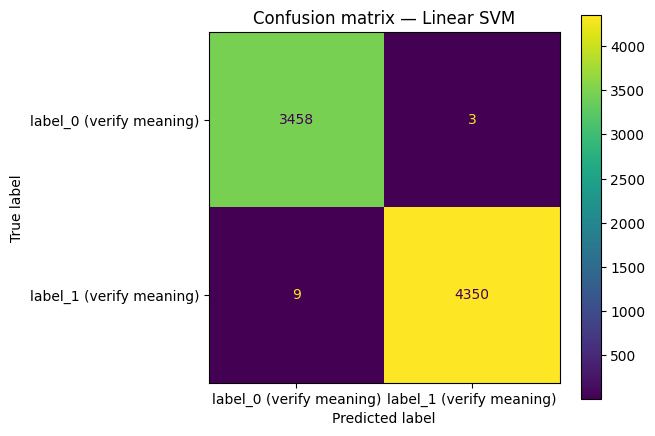

ROC-AUC (decision score): 1.0000
Average precision / PR-AUC (decision score): 1.0000


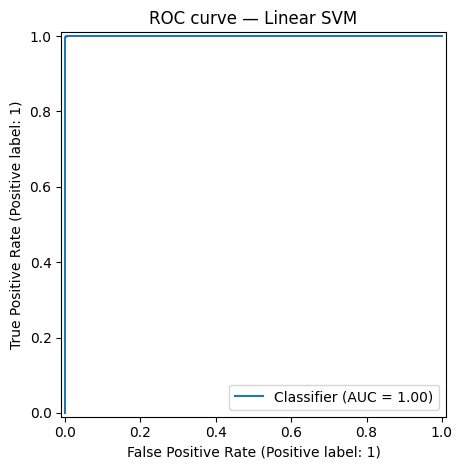

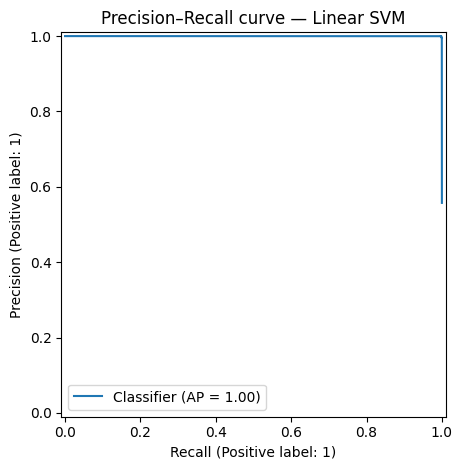

,selected_model,accuracy,precision_label1,recall_label1,f1_label1,false_positive_rate,roc_auc,average_precision
0,Linear SVM,0.9985,0.9993,0.9979,0.9986,0.0009,1.0,1.0


In [ ]:
best_pipeline.fit(X_train, y_train)
y_pred = best_pipeline.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
recall = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
f1 = f1_score(y_test, y_pred, pos_label=1, zero_division=0)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
fpr = fp / (fp + tn) if (fp + tn) else 0.0

print("Selected model:", best_name)
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision for label 1: {precision:.4f}")
print(f"Recall for label 1:    {recall:.4f}")
print(f"F1 for label 1:        {f1:.4f}")
print(f"False-positive rate:   {fpr:.4f}")
print("\\nClassification report:\\n")
print(classification_report(
    y_test, y_pred, labels=[0, 1],
    target_names=[LABEL_NAMES[0], LABEL_NAMES[1]], zero_division=0
))

ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=[LABEL_NAMES[0], LABEL_NAMES[1]]
).plot(values_format="d")
plt.title(f"Confusion matrix — {best_name}")
plt.tight_layout()
plt.show()

if hasattr(best_pipeline, "predict_proba"):
    scores = best_pipeline.predict_proba(X_test)[:, 1]
    score_type = "probability"
elif hasattr(best_pipeline, "decision_function"):
    scores = best_pipeline.decision_function(X_test)
    score_type = "decision score"
else:
    scores = None
    score_type = "unavailable"

roc_auc = np.nan
avg_precision = np.nan
if scores is not None:
    roc_auc = roc_auc_score(y_test, scores)
    avg_precision = average_precision_score(y_test, scores)
    print(f"ROC-AUC ({score_type}): {roc_auc:.4f}")
    print(f"Average precision / PR-AUC ({score_type}): {avg_precision:.4f}")
    RocCurveDisplay.from_predictions(y_test, scores)
    plt.title(f"ROC curve — {best_name}")
    plt.tight_layout()
    plt.show()
    PrecisionRecallDisplay.from_predictions(y_test, scores)
    plt.title(f"Precision–Recall curve — {best_name}")
    plt.tight_layout()
    plt.show()

test_metrics = pd.DataFrame([{
    "selected_model": best_name, "accuracy": accuracy,
    "precision_label1": precision, "recall_label1": recall,
    "f1_label1": f1, "false_positive_rate": fpr,
    "roc_auc": roc_auc, "average_precision": avg_precision
}])
display(test_metrics.round(4))

In [ ]:
joblib.dump(best_pipeline, MODEL_FILE)

metadata = {
    "selected_model": best_name,
    "target_column": "label",
    "label_names": {str(k): v for k, v in LABEL_NAMES.items()},
    "positive_label_for_metrics": 1,
    "training_dataset": EMAIL_FILE,
    "text_fields": ["subject", "body"],
    "selection_metric": "mean 3-fold training CV F1 for label 1",
    "random_seed": SEED,
    "note": "Verify dataset label semantics. Spam is not necessarily verified scam."
}
with open("model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

cv_results.to_csv("cross_validation_comparison.csv", index=False)
test_metrics.to_csv("heldout_test_metrics.csv", index=False)
pd.DataFrame(cm, index=[LABEL_NAMES[0], LABEL_NAMES[1]],
             columns=[LABEL_NAMES[0], LABEL_NAMES[1]]).to_csv("confusion_matrix.csv")

print("Saved:", MODEL_FILE)
print("Saved model metadata and evaluation CSV files.")

Saved: scam_detection_pipeline.pkl
Saved model metadata and evaluation CSV files.


In [ ]:
loaded_model = joblib.load(MODEL_FILE)

def predict_message(message, model=loaded_model):
    if not isinstance(message, str):
        raise TypeError("message must be a string")
    message = message.strip()
    if not message:
        raise ValueError("Message cannot be empty.")
    message = message[:20000]

    predicted_label = int(model.predict([message])[0])
    result = {
        "predicted_label": predicted_label,
        "predicted_class": LABEL_NAMES[predicted_label],
        "score": None,
        "score_type": None
    }

    if hasattr(model, "predict_proba"):
        result["score"] = float(model.predict_proba([message])[0, 1])
        result["score_type"] = "positive-label probability (0 to 1)"
    elif hasattr(model, "decision_function"):
        result["score"] = float(np.ravel(model.decision_function([message]))[0])
        result["score_type"] = "raw decision score (not a probability)"

    return result

# Example text only; not a test-set result.
print(predict_message("Your account has a problem. Visit the link to verify your details."))

{'predicted_label': 1, 'predicted_class': 'label_1 (verify meaning)', 'score': 0.0037255320912670253, 'score_type': 'raw decision score (not a probability)'}


In [ ]:
loaded_model = joblib.load(MODEL_FILE)

def predict_message(message, model=loaded_model):
    if not isinstance(message, str):
        raise TypeError("message must be a string")
    message = message.strip()
    if not message:
        raise ValueError("Message cannot be empty.")
    message = message[:20000]

    predicted_label = int(model.predict([message])[0])
    result = {
        "predicted_label": predicted_label,
        "predicted_class": LABEL_NAMES[predicted_label],
        "score": None,
        "score_type": None
    }

    if hasattr(model, "predict_proba"):
        result["score"] = float(model.predict_proba([message])[0, 1])
        result["score_type"] = "positive-label probability (0 to 1)"
    elif hasattr(model, "decision_function"):
        result["score"] = float(np.ravel(model.decision_function([message]))[0])
        result["score_type"] = "raw decision score (not a probability)"

    return result

# Example text only; not a test-set result.
print(predict_message("Your account has a problem. Visit the link to verify your details."))

{'predicted_label': 1, 'predicted_class': 'label_1 (verify meaning)', 'score': 0.0037255320912670253, 'score_type': 'raw decision score (not a probability)'}


In [ ]:
if "text" not in sms_df.columns:
    raise ValueError("SMS file has no 'text' column.")

sms_text = sms_df["text"].fillna("").astype(str).str.strip()
valid_mask = sms_text.ne("")
sms_text_valid = sms_text[valid_mask].str.slice(0, 20000)
sms_pred = loaded_model.predict(sms_text_valid)

sms_results = pd.DataFrame({
    "message_text": sms_text_valid.to_numpy(),
    "predicted_label": np.asarray(sms_pred, dtype=int),
    "predicted_class": [LABEL_NAMES[int(v)] for v in sms_pred]
})
if hasattr(loaded_model, "predict_proba"):
    sms_results["positive_label_probability"] = loaded_model.predict_proba(sms_text_valid)[:, 1]
elif hasattr(loaded_model, "decision_function"):
    sms_results["raw_decision_score"] = np.ravel(loaded_model.decision_function(sms_text_valid))

sms_results.to_csv("sms_exploratory_predictions_unvalidated.csv", index=False)
display(sms_results.head(10))
print("Saved exploratory SMS predictions; these are not validated SMS metrics.")

,message_text,predicted_label,predicted_class,raw_decision_score
0,Login at may 2 FREE Spin! Marami na ang nakaku...,1,label_1 (verify meaning),0.245630
1,"Condo across Ateneo by Torre Lorenzo, only 12 ...",0,label_0 (verify meaning),-0.278717
2,"papalduhin kita ng 12k ngayon, basta ikaw na b...",1,label_1 (verify meaning),0.138198
3,"B0ss pan@lunin kita sa pinata win 15k, n0w lan...",1,label_1 (verify meaning),0.297034
4,Dito nagsisimula ang saya at panalo! 8P FREE +...,1,label_1 (verify meaning),0.264203
5,okay lang ba makipag deal ako sayo? Cash in ka...,1,label_1 (verify meaning),0.194395
6,Good day I'm Ms.Ivie from multi banking perso...,1,label_1 (verify meaning),0.310606
7,[FEX] Your parcel P6115DDCDD7BA couldn't reach...,1,label_1 (verify meaning),0.089079
8,"Smart reminds you:Your Reward Points (6,309) e...",0,label_0 (verify meaning),-0.024255
9,Your Landbank iAccess account is about to be d...,1,label_1 (verify meaning),0.030071


Saved exploratory SMS predictions; these are not validated SMS metrics.


In [ ]:
from google.colab import files
for path in [
    MODEL_FILE, "model_metadata.json", "cross_validation_comparison.csv",
    "heldout_test_metrics.csv", "confusion_matrix.csv",
    "sms_exploratory_predictions_unvalidated.csv"
]:
    if os.path.exists(path):
        files.download(path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>